# Audit qualité avec Python / Pandas

**Objectif :** rassembler l'audit dans un notebook reproductible, produire
les visualisations et préparer les exports du tableau de bord.

Plusieurs thèmes ont déjà été traités dans les notebooks précédents.
Ils sont repris ici sans être recalculés en double :

| Thème | Déjà traité | Complété dans ce notebook |
|---|---|---|
| Chargement et types | Notebook 01 | Comparaison avec les types déduits par pandas |
| Profilage pandas | Notebooks 01 et 02 | Profil consolidé par colonne |
| Fonctions de contrôle | Notebook 02, `src/dq.py` | Présentation et test des fonctions |
| Âges atypiques | Notebooks 01 et 03 | Moyenne et médiane avant et après exclusion, graphique |
| Tableau des anomalies | Notebooks 02 et 03 | Tableau agrégé avec les lignes à examiner |
| Visualisations | — | Quatre graphiques |
| Détection et correction | Notebooks 01 à 03 (détection) | Table des propositions de correction |

**Aucune donnée n'est modifiée** : les corrections sont seulement proposées.

In [1]:
import platform
import sys
from datetime import datetime
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))
import dq

RUN_DATETIME = datetime.now()
FIGURES_DIR = dq.OUTPUT_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"Run date: {RUN_DATETIME:%Y-%m-%d %H:%M}")
print(f"Python {platform.python_version()}, pandas {pd.__version__}, matplotlib {matplotlib.__version__}")

Run date: 2026-11-24 16:22
Python 3.12.8, pandas 3.1.0, matplotlib 3.11.2


In [2]:
# Chart style: light surface, recessive grid, thin marks
COLORS = {
    "series": "#2a78d6",     # single series
    "series_2": "#eb6834",   # second categorical series
    "FAIL": "#d03b3b",       # certain anomaly
    "REVIEW": "#fab219",     # probable anomaly
    "INFO": "#898781",       # statistical signal to check
    "ink": "#0b0b0b",
    "ink_2": "#52514e",
    "muted": "#898781",
    "grid": "#e1e0d9",
    "axis": "#c3c2b7",
    "surface": "#fcfcfb",
}

plt.rcParams.update({
    "figure.facecolor": COLORS["surface"],
    "axes.facecolor": COLORS["surface"],
    "savefig.facecolor": COLORS["surface"],
    "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"],
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.titleweight": "semibold",
    "axes.titlelocation": "left",
    "axes.titlecolor": COLORS["ink"],
    "axes.labelcolor": COLORS["ink_2"],
    "axes.edgecolor": COLORS["axis"],
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": COLORS["grid"],
    "grid.linewidth": 0.6,
    "xtick.color": COLORS["muted"],
    "ytick.color": COLORS["muted"],
    "xtick.labelcolor": COLORS["ink_2"],
    "ytick.labelcolor": COLORS["ink_2"],
    "legend.frameon": False,
})


def save_figure(fig, name):
    path = FIGURES_DIR / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Saved {path.relative_to(dq.PROJECT_ROOT)}")

## 1. Chargement et vérification des types

Les fichiers sont des CSV séparés par des points-virgules, encodés en UTF-8
avec BOM. L'encodage `utf-8-sig` retire le BOM : sans lui, la première
colonne s'appellerait `\ufeffid_client`.

Deux lectures sont comparées :
- **lecture texte** (`dtype=str`, `keep_default_na=False`), utilisée pour l'audit ;
- **lecture par défaut**, où pandas déduit les types et transforme les cellules vides en NaN.

In [3]:
read_options = {"sep": ";", "encoding": "utf-8-sig"}

datasets = {}
inferred = {}
for file_name in dq.ID_COLUMNS:
    path = dq.RAW_DIR / file_name
    datasets[file_name] = pd.read_csv(path, dtype=str, keep_default_na=False, **read_options)
    inferred[file_name] = pd.read_csv(path, **read_options)

clients_df = datasets["clients.csv"]
products_df = datasets["produits.csv"]

# Same loading as the shared module used by the other notebooks
for file_name, df in datasets.items():
    assert df.equals(dq.load_raw(file_name))

In [4]:
# Compare the text reading with the types inferred by pandas
type_comparison = pd.concat(
    [
        pd.DataFrame({
            "file": file_name,
            "field": datasets[file_name].columns,
            "text_reading": datasets[file_name].dtypes.astype(str).to_numpy(),
            "inferred_type": inferred[file_name].dtypes.astype(str).to_numpy(),
            "missing_as_nan": inferred[file_name].isna().sum().to_numpy(),
        })
        for file_name in datasets
    ],
    ignore_index=True,
)
type_comparison.loc[type_comparison["inferred_type"].ne(type_comparison["text_reading"])
                    | type_comparison["missing_as_nan"].gt(0)]

,file,field,text_reading,inferred_type,missing_as_nan
3,clients.csv,age,str,int64,0
4,clients.csv,email,str,str,1
7,clients.csv,code_postal,str,int64,0
13,produits.csv,categorie,str,str,1
15,produits.csv,prix_unitaire_eur,str,float64,0
16,produits.csv,tva_pct,str,float64,0
17,produits.csv,stock_unites,str,float64,1


**Pourquoi l'audit lit les fichiers en texte :**

- `code_postal` est déduit comme entier : un code commençant par 0
  (par exemple `01000`) perdrait son zéro et deviendrait invalide.
- `stock_unites` est déduit comme décimal (`float64`) à cause d'une seule
  cellule vide : `36` devient `36.0`.
- `age` et `prix_unitaire_eur` seraient convertis silencieusement ;
  une valeur mal saisie (par exemple `12,5`) ferait basculer toute
  la colonne en texte sans avertissement.
- Les cellules vides deviennent NaN et ne se distinguent plus
  d'une chaîne d'espaces.

La lecture en texte conserve la valeur exacte du fichier. Les conversions
sont faites ensuite, colonne par colonne, et les échecs sont comptés
au lieu d'être masqués.

## 2. Profil consolidé

Les fonctions demandées par le TP sont appliquées aux données typées par pandas
(pour `describe` sur les colonnes numériques) et aux données brutes en texte.

In [5]:
for file_name in datasets:
    raw, typed = datasets[file_name], inferred[file_name]
    print(f"=== {file_name}")
    print(f"shape: {raw.shape}")
    print(f"exact duplicate rows (duplicated): {raw.duplicated().sum()}")
    print(f"repeated identifiers: {raw[dq.ID_COLUMNS[file_name]].duplicated().sum()}")
    print(f"missing values with default reading (isna): {typed.isna().sum().sum()}")
    display(typed.describe().T.rename(columns={"50%": "median"}))

=== clients.csv
shape: (10, 11)
exact duplicate rows (duplicated): 0
repeated identifiers: 1
missing values with default reading (isna): 1


,count,mean,std,min,25%,median,75%,max
age,10.0,60.3,55.073789,0.0,35.0,42.5,48.25,172.0
code_postal,10.0,61156.1,4942.470468,59000.0,59147.5,59390.0,59687.50,75001.0


=== produits.csv
shape: (100, 10)
exact duplicate rows (duplicated): 0
repeated identifiers: 1
missing values with default reading (isna): 2


,count,mean,std,min,25%,median,75%,max
prix_unitaire_eur,100.0,106.936000,999.325043,-5.2,3.8,4.85,6.425,9999.9
tva_pct,100.0,7.740000,10.116863,5.5,5.5,5.50,5.500,99.0
stock_unites,99.0,79.424242,45.773642,-12.0,36.0,75.00,116.000,158.0


In [6]:
def profile(df, file_name):
    """One row per column: completeness, distinct values, top value and numeric summary."""
    rows = []
    for column in df.columns:
        values = df[column]
        blank = dq.is_blank(values)
        populated = values[~blank]
        numbers = dq.to_number(values)
        is_numeric = len(populated) > 0 and numbers.notna().sum() == len(populated)
        top = populated.value_counts()

        row = {
            "file": file_name,
            "field": column,
            "detected_type": "numeric" if is_numeric else "text",
            "rows": len(values),
            "populated": int((~blank).sum()),
            "missing": int(blank.sum()),
            "completeness_pct": round((~blank).mean() * 100, 1),
            "distinct": populated.nunique(),
            "top_value": top.index[0] if len(top) else None,
            "top_count": int(top.iloc[0]) if len(top) else 0,
        }
        if is_numeric:
            row.update({
                "min": numbers.min(),
                "mean": round(numbers.mean(), 2),
                "median": numbers.median(),
                "max": numbers.max(),
            })
        rows.append(row)
    return pd.DataFrame(rows)


column_profile = pd.concat(
    [profile(df, file_name) for file_name, df in datasets.items()],
    ignore_index=True,
)
column_profile

,file,field,detected_type,rows,populated,missing,completeness_pct,distinct,top_value,top_count,min,mean,median,max
0,clients.csv,id_client,text,10,10,0,100.0,9,CLI001,2,NaN,NaN,NaN,NaN
1,clients.csv,prenom,text,10,10,0,100.0,10,Camille,1,NaN,NaN,NaN,NaN
2,clients.csv,nom,text,10,10,0,100.0,10,Leroy,1,NaN,NaN,NaN,NaN
3,clients.csv,age,numeric,10,10,0,100.0,10,29,1,0.0,60.30,42.50,172.0
4,clients.csv,email,text,10,9,1,90.0,9,camille.leroy@example.com,1,NaN,NaN,NaN,NaN
5,clients.csv,telephone,text,10,10,0,100.0,10,06 12 34 50 01,1,NaN,NaN,NaN,NaN
6,clients.csv,ville,text,10,10,0,100.0,10,Lille,1,NaN,NaN,NaN,NaN
7,clients.csv,code_postal,numeric,10,10,0,100.0,10,59000,1,59000.0,61156.10,59390.00,75001.0
8,clients.csv,type_client,text,10,10,0,100.0,2,Particulier,5,NaN,NaN,NaN,NaN
9,clients.csv,date_inscription,text,10,10,0,100.0,10,2025-02-14,1,NaN,NaN,NaN,NaN


**Lecture :** le profil confirme les constats du notebook 01 :
- 3 valeurs manquantes (`email`, `categorie`, `stock_unites`) ;
- un identifiant répété dans chaque fichier ;
- une colonne `entreprise_exemple` constante ;
- des écarts importants entre moyenne et médiane pour l'âge et le prix.

## 3. Fonctions de contrôle réutilisables

Les contrôles sont regroupés dans `src/dq.py` et décrits dans
`rules/rules_catalog.csv`.

| Fonction | Rôle |
|---|---|
| `load_raw`, `load_datasets` | Chargement brut en texte, sans conversion |
| `is_blank`, `to_number` | Valeur manquante (NULL, vide, espaces) et conversion sans perte |
| `missing_summary` | Complétude par colonne |
| `tukey_bounds` | Bornes statistiques [Q1 - 1,5 x IQR ; Q3 + 1,5 x IQR] |
| `check_id_populated`, `check_id_unique` | Identifiants obligatoires et uniques |
| `check_populated` | Champs obligatoires, liste lue dans le catalogue |
| `check_email_format`, `check_vat_rate`, ... | Règles de format, de domaine et métier |
| `run_rules` | Exécute toutes les règles et produit les résultats et la table de suivi |

**Ajouter une règle** : une ligne dans le catalogue et une fonction décorée par
`@rule("ID")`. `check_catalog_consistency` signale toute règle du catalogue
sans fonction, et inversement.

In [7]:
catalog = dq.load_rules_catalog()
context = dq.default_context(run_date=RUN_DATETIME.date())
rule_results, violations = dq.run_rules(datasets, catalog, context)

(
    pd.crosstab(catalog["dimension"], catalog["file"], margins=True, margins_name="Total")
    .rename_axis(columns=None)
    .reset_index()
)

,dimension,clients.csv,produits.csv,Total
0,Cohérence,2,2,4
1,Complétude,2,1,3
2,Exactitude,0,3,3
3,Intégrité,3,3,6
4,Unicité,2,1,3
5,Valeurs aberrantes,1,2,3
6,Validité,7,4,11
7,Total,17,16,33


Les fonctions ne dépendent pas des fichiers étudiés : elles peuvent être
testées sur un petit jeu de données construit pour l'occasion, dont le résultat
attendu est connu.

In [8]:
# Test the functions on a small synthetic dataset with known answers
test_clients = pd.DataFrame({
    "id_client": ["T1", "T2", "T2", "  "],
    "email": ["a.b@example.com", "a@@example", "", "x y@example.com"],
    "age": ["30", "121", "17", "abc"],
})

tests = {
    "CLI-INT-01": ([False, False, False, True], ["id_client"]),
    "CLI-INT-02": ([False, True, True, False], ["id_client"]),
    "CLI-VAL-01": ([False, True, False, True], ["email"]),
    "CLI-VAL-04": ([False, True, False, True], ["age"]),
    "CLI-VAL-05": ([False, False, True, False], ["age"]),
}

for rule_id, (expected, fields) in tests.items():
    result = dq.RULES[rule_id](test_clients, fields, context).tolist()
    assert result == expected, (rule_id, result)
    print(f"{rule_id}: OK")

CLI-INT-01: OK
CLI-INT-02: OK
CLI-VAL-01: OK
CLI-VAL-04: OK
CLI-VAL-05: OK


## 4. Âges atypiques

**Méthodes comparées :**

| Méthode | Règle | Justification |
|---|---|---|
| Borne métier certaine | 0 <= âge <= 120 (`CLI-VAL-04`) | Un âge supérieur au record humain (122 ans) est impossible. |
| Borne métier probable | âge >= 18 (`CLI-VAL-05`) | Hypothèse : un client inscrit est majeur. À confirmer. |
| Statistique | Bornes de Tukey (`CLI-OUT-01`) | Ne suppose pas de distribution normale, mais reste fragile avec seulement 10 valeurs. |

Les bornes métier sont retenues pour qualifier les anomalies : elles ne
dépendent pas des autres valeurs du fichier. La méthode de Tukey sert de
signal complémentaire.

In [9]:
ages = dq.to_number(clients_df["age"])
flags = {
    rule_id: set(violations.loc[violations["rule_id"].eq(rule_id), "row_number"])
    for rule_id in ["CLI-VAL-04", "CLI-VAL-05", "CLI-OUT-01"]
}

age_review = pd.DataFrame({
    "row_number": range(1, len(clients_df) + 1),
    "id_client": clients_df["id_client"],
    "age": ages,
})
for rule_id, rows in flags.items():
    age_review[rule_id] = age_review["row_number"].isin(rows)

age_review.loc[age_review[list(flags)].any(axis=1)]

,row_number,id_client,age,CLI-VAL-04,CLI-VAL-05,CLI-OUT-01
4,5,CLI005,150,True,False,True
6,7,CLI007,172,True,False,True
8,9,CLI009,0,False,True,True


In [10]:
# Mean and median before and after excluding invalid ages
impossible = age_review["CLI-VAL-04"]
minor = age_review["CLI-VAL-05"]

age_scenarios = {
    "Toutes les valeurs": ages,
    "Sans âges impossibles (CLI-VAL-04)": ages[~impossible],
    "Sans âges impossibles ni mineurs (CLI-VAL-04, CLI-VAL-05)": ages[~impossible & ~minor],
}

age_comparison = pd.DataFrame([
    {
        "scope": scope,
        "n": values.count(),
        "mean": round(values.mean(), 1),
        "median": values.median(),
        "gap_mean_median": round(values.mean() - values.median(), 1),
        "min": values.min(),
        "max": values.max(),
    }
    for scope, values in age_scenarios.items()
])
age_comparison

,scope,n,mean,median,gap_mean_median,min,max
0,Toutes les valeurs,10,60.3,42.5,17.8,0,172
1,Sans âges impossibles (CLI-VAL-04),8,35.1,39.5,-4.4,0,49
2,"Sans âges impossibles ni mineurs (CLI-VAL-04, ...",7,40.1,41.0,-0.9,29,49


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


Saved outputs\figures\01_client_ages.png


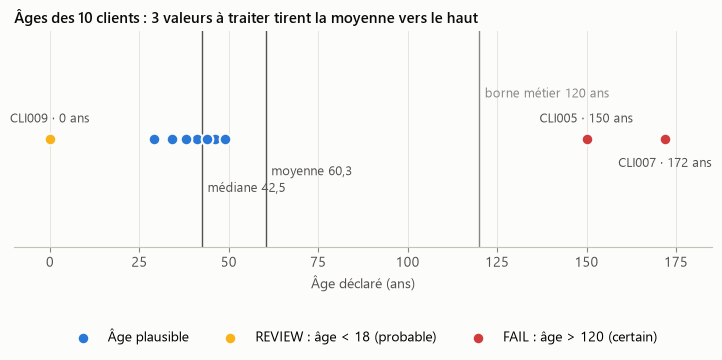

In [11]:
# Figure 1 - client ages: each client is a dot, anomalies are labeled
fig, ax = plt.subplots(figsize=(9, 2.8))

status = pd.Series("Valide", index=age_review.index)
status[minor] = "REVIEW"
status[impossible] = "FAIL"

for label, color, text in [
    ("Valide", COLORS["series"], "Âge plausible"),
    ("REVIEW", COLORS["REVIEW"], "REVIEW : âge < 18 (probable)"),
    ("FAIL", COLORS["FAIL"], "FAIL : âge > 120 (certain)"),
]:
    subset = age_review[status.eq(label)]
    ax.scatter(subset["age"], [0] * len(subset), s=70, color=color,
               edgecolor=COLORS["surface"], linewidth=1.5, zorder=3, label=text)

label_offsets = {"CLI005": (0, 12), "CLI007": (0, -20), "CLI009": (0, 12)}
for _, row in age_review[status.ne("Valide")].iterrows():
    ax.annotate(f"{row['id_client']} · {row['age']:.0f} ans", (row["age"], 0),
                xytext=label_offsets[row["id_client"]], textcoords="offset points",
                ha="center", fontsize=9, color=COLORS["ink_2"])

for value, label, offset in [
    (ages.mean(), f"moyenne {ages.mean():.1f}".replace(".", ","), -26),
    (ages.median(), f"médiane {ages.median():.1f}".replace(".", ","), -38),
]:
    ax.axvline(value, color=COLORS["ink_2"], linewidth=1, zorder=2)
    ax.annotate(label, (value, 0), xytext=(4, offset), textcoords="offset points",
                fontsize=9, color=COLORS["ink_2"])

ax.axvline(120, color=COLORS["muted"], linewidth=1, zorder=1)
ax.annotate("borne métier 120 ans", (120, 0), xytext=(4, 30),
            textcoords="offset points", fontsize=9, color=COLORS["muted"])

ax.set_ylim(-1, 1)
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.grid(axis="y", visible=False)
ax.set_xlim(-10, 185)
ax.set_xlabel("Âge déclaré (ans)")
ax.set_title("Âges des 10 clients : 3 valeurs à traiter tirent la moyenne vers le haut")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=3)

save_figure(fig, "01_client_ages")
plt.show()

**Interprétation :**

- Sur toutes les valeurs, la moyenne (60,3 ans) dépasse la médiane (42,5 ans)
  de près de 18 ans : la distribution est tirée par 150 et 172 ans.
- Sans ces deux âges impossibles, la moyenne tombe à 35,1 ans, sous la médiane
  (39,5) : l'âge 0 tire maintenant la moyenne vers le bas.
- Sans l'âge 0, moyenne (40,1) et médiane (41) se rejoignent. Les 7 âges
  restants (29 à 49 ans) forment une clientèle homogène.
- **La médiane est l'indicateur à publier** tant que les âges ne sont pas
  corrigés : elle varie de 3 ans selon le scénario, contre 25 ans pour la moyenne.

## 5. Tableau des anomalies

Une ligne par règle en échec : dimension, champ, niveau de certitude,
nombre et taux de lignes concernées, puis lignes et identifiants à examiner.
Le détail ligne par ligne reste disponible dans `outputs/anomalies.csv`.

In [12]:
def join_unique(values):
    return ", ".join(dict.fromkeys(str(value) for value in values))


to_review = violations.groupby("rule_id").agg(
    rows_to_review=("row_number", lambda rows: join_unique(sorted(rows))),
    identifiers_to_review=("identifier", join_unique),
)

result_order = pd.CategoricalDtype(["FAIL", "REVIEW", "INFO"], ordered=True)

anomaly_summary = (
    rule_results
    .loc[rule_results["rows_violating"].gt(0)]
    .join(to_review, on="rule_id")
    .astype({"test_result": result_order})
    .sort_values(["test_result", "rows_violating", "rule_id"], ascending=[True, False, True])
    .reset_index(drop=True)
    [["rule_id", "file", "dimension", "field", "rule", "test_result",
      "rows_violating", "violation_rate_pct", "rows_to_review", "identifiers_to_review"]]
)

with pd.option_context("display.max_colwidth", 70):
    display(anomaly_summary)

,rule_id,file,dimension,field,rule,test_result,rows_violating,violation_rate_pct,rows_to_review,identifiers_to_review
0,CLI-INT-02,clients.csv,Intégrité,id_client,Identifiant client unique,FAIL,2,20.0,"1, 2",CLI001
1,CLI-VAL-04,clients.csv,Validité,age,Âge entier compris entre 0 et 120,FAIL,2,20.0,"5, 7","CLI005, CLI007"
2,PRD-COH-01,produits.csv,Cohérence,stock_unites|statut_stock,Produit sans stock non déclaré disponible,FAIL,2,2.0,"21, 40","PRD021, PRD040"
3,PRD-COM-01,produits.csv,Complétude,nom_produit|categorie|conditionnement|prix_unitaire_eur|tva_pct|st...,Champs obligatoires renseignés,FAIL,2,2.0,"5, 15","PRD005, PRD015"
4,PRD-INT-02,produits.csv,Intégrité,id_produit,Identifiant produit unique,FAIL,2,2.0,"1, 2",PRD001
5,CLI-COH-01,clients.csv,Cohérence,ville|code_postal,Code postal cohérent avec la ville,FAIL,1,10.0,8,CLI008
6,CLI-VAL-01,clients.csv,Validité,email,Format d'e-mail valide,FAIL,1,10.0,4,CLI004
7,CLI-VAL-02,clients.csv,Validité,telephone,Format de téléphone français valide,FAIL,1,10.0,6,CLI006
8,PRD-VAL-02,produits.csv,Validité,tva_pct,Taux de TVA légal,FAIL,1,1.0,30,PRD030
9,PRD-COH-02,produits.csv,Cohérence,stock_unites|statut_stock,Statut conforme au seuil de stock faible,REVIEW,28,28.0,"4, 7, 8, 11, 16, 22, 25, 27, 30, 32, 34, 35, 39, 43, 48, 49, 52, 6...","PRD004, PRD007, PRD008, PRD011, PRD016, PRD022, PRD025, PRD027, PR..."


In [13]:
print(f"Rules executed: {len(rule_results)}")
print(f"Rules violated: {len(anomaly_summary)}")
display(anomaly_summary.groupby("test_result", observed=True)["rows_violating"].agg(["count", "sum"])
        .rename(columns={"count": "rules", "sum": "rows_flagged"}).reset_index())

Rules executed: 33
Rules violated: 19


,test_result,rules,rows_flagged
0,FAIL,9,14
1,REVIEW,8,41
2,INFO,2,15


## 6. Visualisations

Trois figures complètent celle des âges :
1. la distribution des prix et des stocks ;
2. les anomalies par dimension et par champ ;
3. les indicateurs du catalogue par catégorie.

Couleurs : bleu pour les valeurs sans anomalie ; rouge pour `FAIL`
(certain), jaune pour `REVIEW` (probable) et gris pour `INFO` (à vérifier).

Saved outputs\figures\02_price_stock_distributions.png


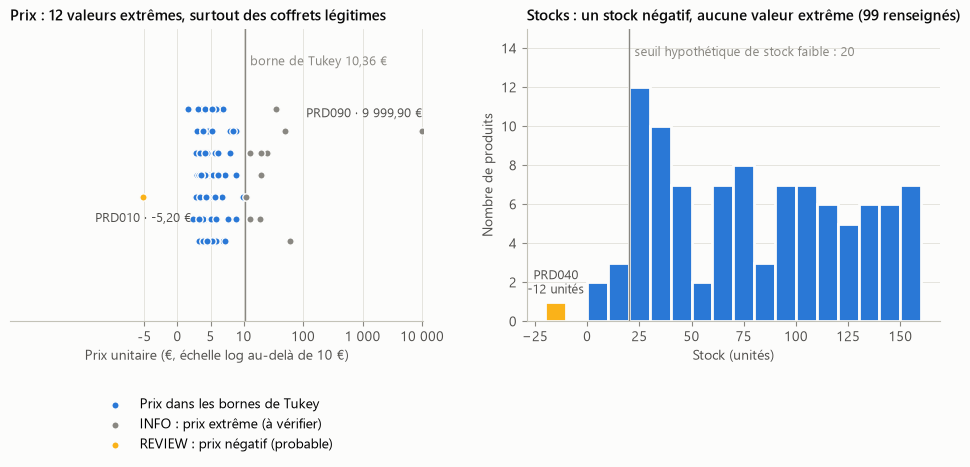

In [14]:
# Figure 2 - price and stock distributions
prices = dq.to_number(products_df["prix_unitaire_eur"])
stocks = dq.to_number(products_df["stock_unites"])
price_low, price_high = dq.tukey_bounds(prices.dropna())

fig, (ax_price, ax_stock) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"wspace": 0.25})

# Prices on a symmetric log scale: the 9 999,90 EUR value would crush a linear axis
jitter = pd.Series(range(len(prices))).mod(7).sub(3).mul(0.09).to_numpy()
price_status = pd.Series("Valide", index=products_df.index)
price_status[prices.gt(price_high) | prices.lt(price_low)] = "INFO"
price_status[prices.lt(0)] = "REVIEW"

for label, color, text in [
    ("Valide", COLORS["series"], "Prix dans les bornes de Tukey"),
    ("INFO", COLORS["INFO"], "INFO : prix extrême (à vérifier)"),
    ("REVIEW", COLORS["REVIEW"], "REVIEW : prix négatif (probable)"),
]:
    mask = price_status.eq(label).to_numpy()
    ax_price.scatter(prices[mask], jitter[mask], s=28, color=color,
                     edgecolor=COLORS["surface"], linewidth=1, zorder=3, label=text)

for row_id, text, offset, align in [("PRD010", "PRD010 · -5,20 €", (0, -18), "center"),
                                    ("PRD090", "PRD090 · 9 999,90 €", (0, 10), "right")]:
    position = products_df.index[products_df["id_produit"].eq(row_id)][0]
    ax_price.annotate(text, (prices[position], jitter[position]), xytext=offset, ha=align,
                      textcoords="offset points", fontsize=9, color=COLORS["ink_2"])

ax_price.axvline(price_high, color=COLORS["muted"], linewidth=1, zorder=1)
ax_price.annotate(f"borne de Tukey {price_high:.2f} €".replace(".", ","), (price_high, 0.45), xytext=(4, 0),
                  textcoords="offset points", fontsize=9, color=COLORS["muted"])
ax_price.set_xscale("symlog", linthresh=10)
ax_price.set_xticks([-5, 0, 5, 10, 100, 1000, 10000])
ax_price.set_xticklabels(["-5", "0", "5", "10", "100", "1 000", "10 000"])
ax_price.xaxis.set_minor_locator(matplotlib.ticker.NullLocator())
ax_price.set_ylim(-0.6, 0.6)
ax_price.set_yticks([])
ax_price.spines["left"].set_visible(False)
ax_price.grid(axis="y", visible=False)
ax_price.set_xlabel("Prix unitaire (€, échelle log au-delà de 10 €)")
ax_price.set_title("Prix : 12 valeurs extrêmes, surtout des coffrets légitimes")
ax_price.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=1)

# Stocks: histogram with 10-unit bins; the negative bin carries the REVIEW color
bins = list(range(-20, 170, 10))
counts, edges, patches = ax_stock.hist(stocks.dropna(), bins=bins, color=COLORS["series"],
                                       edgecolor=COLORS["surface"], linewidth=2)
for patch, left in zip(patches, edges[:-1]):
    if left < 0:
        patch.set_facecolor(COLORS["REVIEW"])
ax_stock.annotate("PRD040\n-12 unités", (-15, 1), xytext=(0, 6), textcoords="offset points",
                  ha="center", fontsize=9, color=COLORS["ink_2"])
ax_stock.axvline(20, color=COLORS["muted"], linewidth=1)
ax_stock.set_ylim(0, counts.max() + 3)
ax_stock.annotate("seuil hypothétique de stock faible : 20", (20, counts.max() + 1.6), xytext=(4, 0),
                  textcoords="offset points", fontsize=9, color=COLORS["muted"])
ax_stock.set_xlabel("Stock (unités)")
ax_stock.set_ylabel("Nombre de produits")
ax_stock.set_title("Stocks : un stock négatif, aucune valeur extrême (99 renseignés)")
ax_stock.grid(axis="x", visible=False)

save_figure(fig, "02_price_stock_distributions")
plt.show()

Saved outputs\figures\03_anomalies_by_dimension_and_field.png


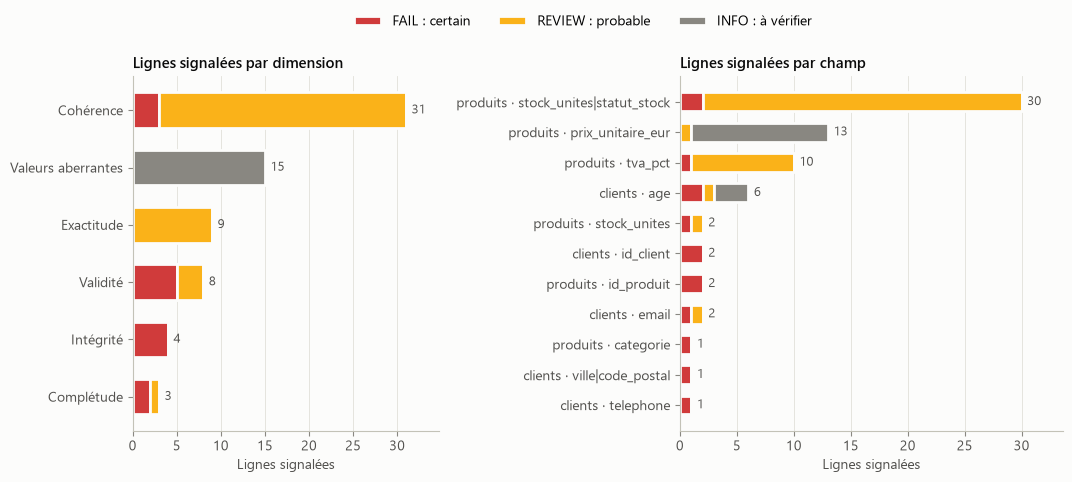

In [15]:
# Figure 3 - anomalies by dimension and by field, split by result level
results = ["FAIL", "REVIEW", "INFO"]
labels = {
    "FAIL": "FAIL : certain",
    "REVIEW": "REVIEW : probable",
    "INFO": "INFO : à vérifier",
}

by_dimension = (
    violations.groupby(["dimension", "test_result"]).size().unstack(fill_value=0)
    .reindex(columns=results, fill_value=0)
)
by_dimension = by_dimension.loc[by_dimension.sum(axis=1).sort_values().index]

by_field = (
    violations.assign(field=violations["file"].str.replace(".csv", "") + " · " + violations["field"])
    .groupby(["field", "test_result"]).size().unstack(fill_value=0)
    .reindex(columns=results, fill_value=0)
)
by_field = by_field.loc[by_field.sum(axis=1).sort_values().index]

fig, (ax_dim, ax_field) = plt.subplots(
    1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1, 1.25], "wspace": 0.7}
)

for ax, table, title in [
    (ax_dim, by_dimension, "Lignes signalées par dimension"),
    (ax_field, by_field, "Lignes signalées par champ"),
]:
    left = pd.Series(0, index=table.index)
    for result in results:
        ax.barh(table.index, table[result], left=left, height=0.62,
                color=COLORS[result], edgecolor=COLORS["surface"], linewidth=2,
                label=labels[result])
        left += table[result]
    for position, total in enumerate(left):
        ax.annotate(str(total), (total, position), xytext=(4, 0), textcoords="offset points",
                    va="center", fontsize=9, color=COLORS["ink_2"])
    ax.set_title(title)
    ax.set_xlabel("Lignes signalées")
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, left.max() * 1.12)

handles, legend_labels = ax_dim.get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.04))

save_figure(fig, "03_anomalies_by_dimension_and_field")
plt.show()

**Lecture :** la cohérence domine en volume (31 lignes), à cause de la règle
du seuil de stock faible (28 lignes, `REVIEW`). Les anomalies certaines (`FAIL`)
sont peu nombreuses mais touchent des champs critiques : identifiants,
contact, âge, code postal et TVA. Les signaux `INFO` concernent surtout le prix.

Saved outputs\figures\04_catalogue_by_category.png


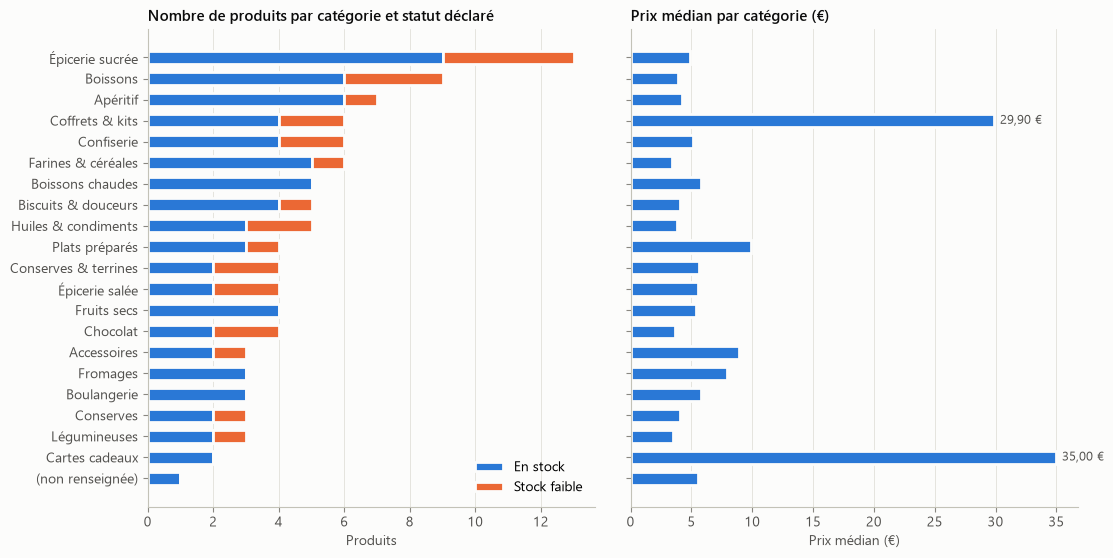

In [16]:
# Figure 4 - catalogue by category: product count by stock status, and median price
category_label = products_df["categorie"].where(~dq.is_blank(products_df["categorie"]), "(non renseignée)")
catalogue = products_df.assign(categorie=category_label, prix=prices, stock=stocks)

by_category = catalogue.groupby("categorie").agg(
    products=("id_produit", "size"),
    in_stock=("statut_stock", lambda status: status.eq("En stock").sum()),
    low_stock=("statut_stock", lambda status: status.eq("Stock faible").sum()),
    median_price=("prix", "median"),
)
order = by_category.sort_values(["products", "median_price"]).index
by_category = by_category.loc[order]

fig, (ax_count, ax_price) = plt.subplots(
    1, 2, figsize=(12, 6.2), sharey=True, gridspec_kw={"wspace": 0.08}
)

ax_count.barh(by_category.index, by_category["in_stock"], height=0.62,
              color=COLORS["series"], edgecolor=COLORS["surface"], linewidth=2, label="En stock")
ax_count.barh(by_category.index, by_category["low_stock"], left=by_category["in_stock"], height=0.62,
              color=COLORS["series_2"], edgecolor=COLORS["surface"], linewidth=2, label="Stock faible")
ax_count.set_title("Nombre de produits par catégorie et statut déclaré")
ax_count.set_xlabel("Produits")
ax_count.grid(axis="y", visible=False)
ax_count.legend(loc="lower right")

ax_price.barh(by_category.index, by_category["median_price"], height=0.62,
              color=COLORS["series"], edgecolor=COLORS["surface"], linewidth=2)
ax_price.set_title("Prix médian par catégorie (€)")
ax_price.set_xlabel("Prix médian (€)")
ax_price.grid(axis="y", visible=False)
for category in ["Coffrets & kits", "Cartes cadeaux"]:
    position = list(by_category.index).index(category)
    value = by_category.loc[category, "median_price"]
    ax_price.annotate(f"{value:.2f} €".replace(".", ","), (value, position), xytext=(4, 0),
                      textcoords="offset points", va="center", fontsize=9, color=COLORS["ink_2"])

save_figure(fig, "04_catalogue_by_category")
plt.show()

**Lecture :**
- « Épicerie sucrée » est la catégorie la plus fournie (13 produits).
- Le **prix médian** est utilisé plutôt que la moyenne : la moyenne des
  « Coffrets & kits » dépasse 1 693 € à cause du seul prix de 9 999,90 €,
  alors que leur médiane est de 29,90 €.
- Le statut « Stock faible » apparaît dans presque toutes les catégories ;
  la règle `PRD-COH-02` a montré qu'il ne reflète pas la quantité en stock.

## 7. Propositions de correction

**Principe : la détection et la correction sont séparées.**
Aucune valeur n'est remplacée dans ce notebook. Pour chaque anomalie certaine
ou probable (`FAIL` ou `REVIEW`), la table ci-dessous indique :

- la valeur observée et la règle concernée ;
- la valeur proposée, ou la stratégie lorsque l'information est inconnue ;
- la justification et la source de validation nécessaire.

Les signaux `INFO` ne reçoivent pas de proposition : une valeur extrême
n'est pas une erreur. Les valeurs inconnues ne sont jamais inventées :
elles restent vides et sont signalées « à collecter ».

In [17]:
proposals = []


def propose(rule_id, identifier, proposed_value, strategy, justification, source, field=None):
    """Record a proposal for an existing violation (the violation must exist)."""
    match = violations.loc[violations["rule_id"].eq(rule_id) & violations["identifier"].eq(identifier)]
    if field is not None:
        match = match.loc[match["field"].eq(field)]
    assert len(match) >= 1, f"No violation for {rule_id} / {identifier}"

    for violation in match.itertuples(index=False):
        proposals.append({
            "rule_id": rule_id,
            "file": violation.file,
            "row_number": violation.row_number,
            "identifier": identifier,
            "field": violation.field,
            "observed_value": violation.observed_value,
            "test_result": violation.test_result,
            "proposed_value": proposed_value,
            "strategy": strategy,
            "justification": justification,
            "validation_source": source,
            "status": "À valider",
        })

In [18]:
# ---- Clients
propose("CLI-INT-02", "CLI001", "CLI001 (Camille Leroy) / nouvel identifiant (Thomas Dubois)",
        "Nouvel identifiant",
        "Deux clients différents partagent CLI001 : supprimer une ligne ferait perdre un client.",
        "CRM : date de création et historique des commandes de chaque client")
propose("CLI-COM-02", "CLI003", None, "Valeur inconnue : à collecter",
        "Aucune source ne permet de déduire l'e-mail ; le client reste joignable par téléphone.",
        "Contact du client")
propose("CLI-VAL-01", "CLI004", "hugo.petit@example.com", "Correction proposée",
        "Double @ et domaine sans extension ; les 8 autres e-mails suivent prenom.nom@example.com.",
        "Confirmation par le client")
propose("CLI-VAL-02", "CLI006", None, "Valeur inconnue : à collecter",
        "Numéro tronqué : la suite des autres numéros suggère une valeur, mais un téléphone ne se devine pas.",
        "Contact du client")
for identifier in ["CLI005", "CLI007"]:
    propose("CLI-VAL-04", identifier, None, "Valeur inconnue : exclure des statistiques et collecter",
            "Âge impossible ; une faute de frappe est probable mais la valeur exacte est inconnue.",
            "Date de naissance déclarée par le client")
propose("CLI-VAL-05", "CLI009", None, "Valeur inconnue : exclure des statistiques et collecter",
        "Âge 0 : probable valeur par défaut saisie lorsque l'âge est inconnu.",
        "Date de naissance déclarée par le client")
propose("CLI-COH-01", "CLI008", "62300 (si la ville Lens est confirmée)", "Correction proposée",
        "75001 est un code postal parisien ; Lens correspond à 62300. Le champ erroné reste à identifier.",
        "Adresse postale du client, Base Adresse Nationale")

# ---- Products
propose("PRD-INT-02", "PRD001", "PRD001 (Gaufres artisanales) / nouvel identifiant (Spéculoos pur beurre)",
        "Nouvel identifiant",
        "Deux produits différents partagent PRD001 : ventes et stocks risquent d'être mélangés.",
        "ERP : fiches produits et historique des ventes")
propose("PRD-COM-01", "PRD005", "Boulangerie", "Correction proposée",
        "Produit proche de PRD086 « Pain d'épices au miel », classé en Boulangerie.",
        "Chef de produit, référentiel des catégories", field="categorie")
propose("PRD-COM-01", "PRD015", None, "Valeur inconnue : à collecter",
        "Aucune source ne permet de déduire la quantité en stock.",
        "Inventaire physique", field="stock_unites")
propose("PRD-VAL-01", "PRD010", "5.2", "Correction proposée",
        "Probable erreur de signe : les autres confitures (pot 320 g) coûtent 5,40 € et 5,60 €.",
        "Fiche tarifaire")
propose("PRD-VAL-02", "PRD030", "5.5", "Correction proposée",
        "Taux inexistant ; les condiments relèvent du taux réduit, comme les autres produits d'épicerie salée.",
        "Service comptable (CGI / BOFiP)")
propose("PRD-VAL-03", "PRD040", None, "Valeur inconnue : à collecter",
        "Stock négatif physiquement impossible.",
        "Inventaire physique")
propose("PRD-COH-01", "PRD021", "Rupture de stock", "Correction proposée",
        "Stock nul déclaré « En stock » ; la modalité « Rupture de stock » est à ajouter au domaine.",
        "Responsable des stocks")
propose("PRD-COH-01", "PRD040", None, "Recalcul après inventaire",
        "Le statut dépend du stock réel, inconnu tant que l'inventaire n'est pas fait.",
        "Inventaire physique")
propose("PRD-EXA-01", "PRD024", "5.5", "Correction proposée",
        "Les boissons non alcoolisées relèvent du taux réduit de 5,5 %.",
        "Service comptable (CGI / BOFiP)")
for identifier in ["PRD096", "PRD097"]:
    propose("PRD-EXA-02", identifier, "Non applicable à l'émission", "Correction proposée",
            "Bon à usages multiples : la TVA est due lors de l'utilisation de la carte.",
            "Service comptable")
for identifier in violations.loc[violations["rule_id"].eq("PRD-EXA-03"), "identifier"]:
    propose("PRD-EXA-03", identifier, "20.0", "Correction proposée",
            "Les produits de confiserie sont exclus du taux réduit.",
            "Service comptable (CGI / BOFiP)")

# Stock status: proposed value recomputed from the hypothetical threshold
threshold = context["low_stock_threshold"]
for violation in violations.loc[violations["rule_id"].eq("PRD-COH-02")].itertuples(index=False):
    stock = dq.to_number(products_df["stock_unites"]).iloc[violation.row_number - 1]
    expected = "Stock faible" if stock < threshold else "En stock"
    propose("PRD-COH-02", violation.identifier, expected, "Recalcul après validation du seuil",
            f"Stock de {stock:.0f} unités pour un seuil hypothétique de {threshold} unités.",
            "Responsable des stocks (validation du seuil)")

correction_proposals = pd.DataFrame(proposals)
print(f"Proposals: {len(correction_proposals)}")

Proposals: 55


In [19]:
# Traceability check: every FAIL or REVIEW violation has exactly one proposal
key = ["rule_id", "row_number", "field"]
to_correct = violations.loc[violations["test_result"].isin(["FAIL", "REVIEW"]), key]

missing = to_correct.merge(correction_proposals[key], how="left", indicator=True)
missing = missing.loc[missing["_merge"].eq("left_only")]
assert missing.empty, missing
assert not correction_proposals.duplicated(key).any()

print(f"FAIL or REVIEW violations: {len(to_correct)}")
print(f"Violations with a proposal: {len(to_correct) - len(missing)}")

FAIL or REVIEW violations: 55
Violations with a proposal: 55


In [20]:
with pd.option_context("display.max_colwidth", 60, "display.max_rows", 80):
    display(correction_proposals.drop(columns=["file", "status"]))

,rule_id,row_number,identifier,field,observed_value,test_result,proposed_value,strategy,justification,validation_source
0,CLI-INT-02,1,CLI001,id_client,'CLI001',FAIL,CLI001 (Camille Leroy) / nouvel identifiant (Thomas Dubois),Nouvel identifiant,Deux clients différents partagent CLI001 : supprimer une...,CRM : date de création et historique des commandes de ch...
1,CLI-INT-02,2,CLI001,id_client,'CLI001',FAIL,CLI001 (Camille Leroy) / nouvel identifiant (Thomas Dubois),Nouvel identifiant,Deux clients différents partagent CLI001 : supprimer une...,CRM : date de création et historique des commandes de ch...
2,CLI-COM-02,3,CLI003,email,'',REVIEW,NaN,Valeur inconnue : à collecter,Aucune source ne permet de déduire l'e-mail ; le client ...,Contact du client
3,CLI-VAL-01,4,CLI004,email,'hugo.petit@@example',FAIL,hugo.petit@example.com,Correction proposée,Double @ et domaine sans extension ; les 8 autres e-mail...,Confirmation par le client
4,CLI-VAL-02,6,CLI006,telephone,'06 12',FAIL,NaN,Valeur inconnue : à collecter,Numéro tronqué : la suite des autres numéros suggère une...,Contact du client
5,CLI-VAL-04,5,CLI005,age,'150',FAIL,NaN,Valeur inconnue : exclure des statistiques et collecter,Âge impossible ; une faute de frappe est probable mais l...,Date de naissance déclarée par le client
6,CLI-VAL-04,7,CLI007,age,'172',FAIL,NaN,Valeur inconnue : exclure des statistiques et collecter,Âge impossible ; une faute de frappe est probable mais l...,Date de naissance déclarée par le client
7,CLI-VAL-05,9,CLI009,age,'0',REVIEW,NaN,Valeur inconnue : exclure des statistiques et collecter,Âge 0 : probable valeur par défaut saisie lorsque l'âge ...,Date de naissance déclarée par le client
8,CLI-COH-01,8,CLI008,ville|code_postal,ville='Lens' | code_postal='75001',FAIL,62300 (si la ville Lens est confirmée),Correction proposée,75001 est un code postal parisien ; Lens correspond à 62...,"Adresse postale du client, Base Adresse Nationale"
9,PRD-INT-02,1,PRD001,id_produit,'PRD001',FAIL,PRD001 (Gaufres artisanales) / nouvel identifiant (Spécu...,Nouvel identifiant,Deux produits différents partagent PRD001 : ventes et st...,ERP : fiches produits et historique des ventes


In [21]:
correction_proposals.groupby("strategy").size().reset_index(name="proposals")

,strategy,proposals
0,Correction proposée,15
1,Nouvel identifiant,4
2,Recalcul après inventaire,1
3,Recalcul après validation du seuil,28
4,Valeur inconnue : exclure des statistiques et ...,3
5,Valeur inconnue : à collecter,4


**Lecture :**
- Toutes les anomalies certaines ou probables ont une proposition traçable,
  avec une source de validation.
- Les **valeurs inconnues ne sont pas devinées** : e-mail, téléphone, âges
  et stocks restent vides en attendant une source fiable. Les âges invalides
  sont exclus des statistiques plutôt que remplacés par une moyenne.
- Les identifiants répétés sont traités par **attribution d'un nouvel
  identifiant**, jamais par suppression d'une ligne.
- Les 28 statuts de stock ne seront recalculés qu'après validation du seuil.

L'application des corrections se fera dans une copie de travail, après
validation de chaque ligne, avec la date et l'auteur de la correction.

## 8. Exports pour le tableau de bord

Le notebook 03 exporte déjà les résultats des règles (`rule_results.csv`)
et la table de suivi des anomalies (`anomalies.csv`). Ce notebook n'exporte
que ce qu'il produit en plus et dont le tableau de bord a besoin :

| Fichier | Contenu |
|---|---|
| `column_profile.csv` | Profil et complétude par colonne |
| `numeric_stats.csv` | Statistiques des âges, prix et stocks, avant et après exclusion des valeurs invalides |
| `category_stats.csv` | Indicateurs du catalogue par catégorie |
| `correction_proposals.csv` | Propositions de correction à valider |
| `run_metadata.csv` | Date d'exécution et version des fichiers analysés |

Ces fichiers ne contiennent que des agrégats et des anomalies,
pas les données clients complètes.

In [22]:
category_stats = catalogue.groupby("categorie").agg(
    products=("id_produit", "size"),
    mean_price=("prix", "mean"),
    median_price=("prix", "median"),
    min_price=("prix", "min"),
    max_price=("prix", "max"),
    total_stock=("stock", "sum"),
    missing_stock=("stock", lambda stock: stock.isna().sum()),
    in_stock=("statut_stock", lambda status: status.eq("En stock").sum()),
    low_stock=("statut_stock", lambda status: status.eq("Stock faible").sum()),
).round(2).reset_index()

negative_rows = violations.loc[violations["rule_id"].eq("PRD-VAL-01"), "row_number"] - 1
negative_price = products_df.index.isin(negative_rows)

numeric_stats = pd.DataFrame([
    {
        "file": file_name,
        "field": field,
        "scope": scope,
        "n": values.count(),
        "mean": round(values.mean(), 2),
        "std": round(values.std(), 2),
        "min": values.min(),
        "q1": values.quantile(0.25),
        "median": values.median(),
        "q3": values.quantile(0.75),
        "max": values.max(),
    }
    for file_name, field, scope, values in [
        ("clients.csv", "age", "Toutes les valeurs", ages),
        ("clients.csv", "age", "Sans âges impossibles ni mineurs", ages[~impossible & ~minor]),
        ("produits.csv", "prix_unitaire_eur", "Toutes les valeurs", prices),
        ("produits.csv", "prix_unitaire_eur", "Sans prix négatif", prices[~negative_price]),
        ("produits.csv", "stock_unites", "Toutes les valeurs", stocks),
    ]
])

run_metadata = pd.DataFrame([
    {
        **dq.file_fingerprint(file_name),
        "rows": df.shape[0],
        "columns": df.shape[1],
        "rules_executed": int(rule_results["file"].eq(file_name).sum()),
        "run_datetime": RUN_DATETIME.isoformat(timespec="seconds"),
        "python_version": platform.python_version(),
        "pandas_version": pd.__version__,
    }
    for file_name, df in datasets.items()
])

display(numeric_stats)
display(run_metadata)

,file,field,scope,n,mean,std,min,q1,median,q3,max
0,clients.csv,age,Toutes les valeurs,10,60.30,55.07,0.0,35.0,42.50,48.250,172.0
1,clients.csv,age,Sans âges impossibles ni mineurs,7,40.14,7.01,29.0,36.0,41.00,45.000,49.0
2,produits.csv,prix_unitaire_eur,Toutes les valeurs,100,106.94,999.33,-5.2,3.8,4.85,6.425,9999.9
3,produits.csv,prix_unitaire_eur,Sans prix négatif,99,108.07,1004.35,1.6,3.8,4.90,6.450,9999.9
4,produits.csv,stock_unites,Toutes les valeurs,99,79.42,45.77,-12.0,36.0,75.00,116.000,158.0


,file,sha256,size_bytes,rows,columns,rules_executed,run_datetime,python_version,pandas_version
0,clients.csv,66ae9e333e5f1ac7232267acca03cfff2f7ac20dd2f80b...,1544,10,11,17,2026-11-24T16:22:51,3.12.8,3.1.0
1,produits.csv,a53a10d0677d7b113ba5c4ea69c7237560effd74a29b0b...,14204,100,10,16,2026-11-24T16:22:51,3.12.8,3.1.0


In [23]:
exports = {
    "column_profile.csv": column_profile,
    "numeric_stats.csv": numeric_stats,
    "category_stats.csv": category_stats,
    "correction_proposals.csv": correction_proposals,
    "run_metadata.csv": run_metadata,
}

for name, table in exports.items():
    table.to_csv(dq.OUTPUT_DIR / name, sep=";", index=False, encoding="utf-8-sig")
    print(f"{name}: {len(table)} rows")

column_profile.csv: 21 rows
numeric_stats.csv: 5 rows
category_stats.csv: 21 rows
correction_proposals.csv: 55 rows
run_metadata.csv: 2 rows


## Synthèse

- Les données sont lues en texte pour ne perdre aucune valeur ; les types
  déduits par pandas auraient masqué des anomalies (codes postaux, stocks).
- 33 règles exécutées, 19 en échec ; toutes les anomalies certaines ou
  probables ont une proposition de correction traçable.
- La médiane est l'indicateur d'âge et de prix à retenir tant que les valeurs
  aberrantes ne sont pas corrigées.
- Les figures sont enregistrées dans `outputs/figures/` et les tables
  dans `outputs/` pour le tableau de bord.